# nb02 · L1 势能面健全性与轨迹稳定性

**目的**（`validation_methods_L0-L5.md` L1）：在不依赖 DFT 参考的情况下，先排除明显病理。

L1 的特殊之处是它**几乎全是 S 级证据**（reference-free 自洽性检查）：不问模型准不准，
只问势能面本身是不是一个合法的势能面。它同时是整套评估的**门控**——
L1 挂了就不该把算力花在 L4/L5 上。

七项检查：

1. Ge–Ge / Ge–Sb / Ge–Te / Sb–Sb / Sb–Te / Te–Te 六条二体 PEC；
2. PEC 的连续性、短程排斥、energy–force 数值导数一致性；
3. 平移、旋转、净力、应力数值导数；
4. 0.85–1.15 线性晶格缩放的不松弛能量扫描；
5. 高温稳定性与最小原子间距分布；
6. 3.0 fs 与 1.5 fs 的时间步敏感性；
7. NVE 能量漂移与质心漂移。

MD 探针全部跑在 phase-1 AIMD preflight 的**同一个起始构型与协议**上
（306 原子、0.0309 at/Å³、1200 K、POTIM 3.0 fs），因此 NVE 漂移是一次真正同条件的 A 级对照。

In [1]:
import os
# per-model results/data (results/models/<key>/); without it mlipeval falls back to the
# flat pre-2026-09 layout, which no longer holds current results
os.environ.setdefault("MLIPEVAL_MODEL", "mace_mpa0")
import sys, json
sys.path.insert(0, "../scripts")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mlipeval import datasets, paths, protocols
from mlipeval.cache import cached_binary_pecs
from mlipeval.calculators import model_spec_only
from mlipeval.io_vasp import read_poscar
from mlipeval.l1_pes import THRESHOLDS, l1_gate
from mlipeval.md_runner import load_md
from mlipeval.plotting import pair_color, species_color, use_style

use_style()
pd.set_option("display.width", 210)
pd.set_option("display.max_colwidth", 60)

results = json.loads((paths.RESULTS / "L1_mace_mpa0.json").read_text())
by_id = {r["metric_id"]: r for r in results["results"]}
print("L1 结果条目:", len(by_id))
print("探针结构:", results["context"]["probe_structure"])
display(pd.Series(THRESHOLDS).to_frame("阈值"))

L1 结果条目: 23
探针结构: $MLIPEVAL_WORKSPACE/phase1_vasp_inputs_20260828/H0_preflight_03_nve1200/POSCAR


,阈值
pec_min_repulsion_r,1.600000
pec_force_mismatch_rel,0.050000
pec_convergence_ratio,2.500000
scan_smoothness_ratio,25.000000
force_consistency_rel,0.005000
translation_energy_tol,0.000001
rotation_energy_tol,0.000010
net_force_tol,0.000001
stress_consistency_rel,0.050000
nve_drift_tol,5.000000


## 1. 六条二体势能曲线

在 30 Å 的非周期盒子里放两个原子，扫 r = 1.0–8.0 Å（步长 0.02 Å），能量以最大间距为零点。
这是唯一能把"模型在极短程会不会崩"直接看出来的图。

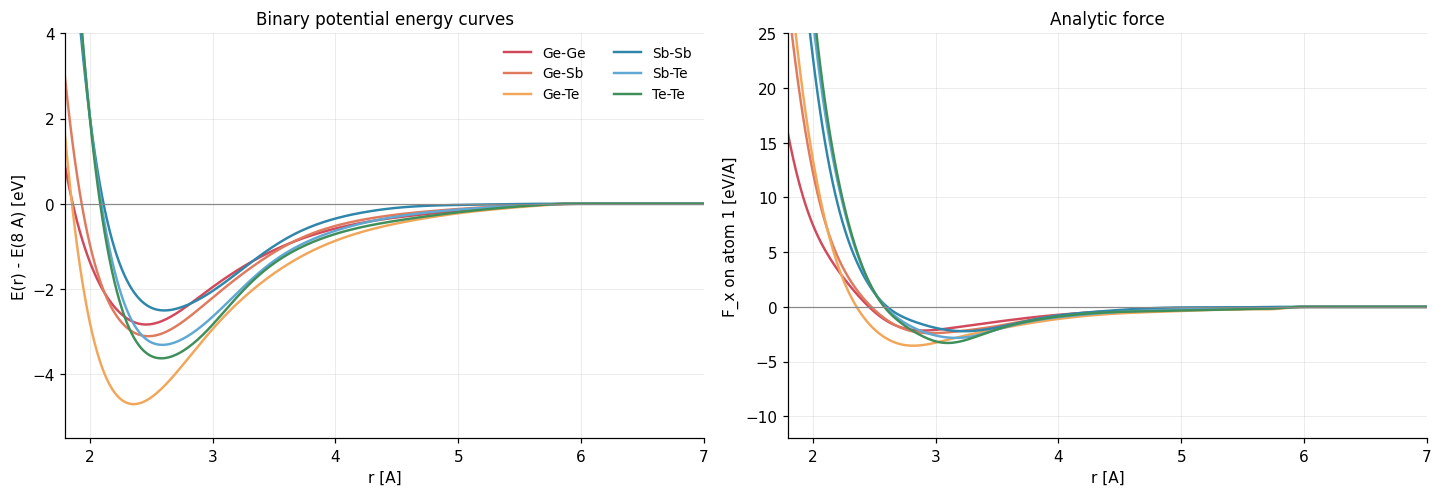

,pair,r_min (A),E_min (eV),短程单调排斥,|F_num-F_ana|/max|F|,O(h^2) 收敛比,非有限值
0,Ge-Ge,2.46,-2.8322,True,0.0026,3.9217,0
1,Ge-Sb,2.48,-3.1064,True,0.0041,3.8785,0
2,Ge-Te,2.36,-4.7006,True,0.0022,3.9283,0
3,Sb-Sb,2.60,-2.5020,True,0.0055,3.6924,0
4,Sb-Te,2.60,-3.3092,True,0.0022,3.8934,0
5,Te-Te,2.58,-3.6260,True,0.0021,3.9301,0


In [2]:
# The six curves are ~2100 dimer evaluations; they are cached by the L1 PBS job,
# so this cell is a read here rather than a computation.
model = model_spec_only()
pecs = cached_binary_pecs(model, ("Ge", "Sb", "Te"), r_min=1.0, r_max=8.0, dr=0.02)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for key, pec in pecs.items():
    axes[0].plot(pec.r, pec.energy, color=pair_color(key), label=key)
    axes[1].plot(pec.r, pec.force_analytic, color=pair_color(key), label=key)
axes[0].axhline(0, color="#888", lw=0.8)
axes[0].set_xlim(1.8, 7.0); axes[0].set_ylim(-5.5, 4.0)
axes[0].set_xlabel("r [A]"); axes[0].set_ylabel("E(r) - E(8 A) [eV]")
axes[0].set_title("Binary potential energy curves"); axes[0].legend(ncol=2)
axes[1].axhline(0, color="#888", lw=0.8)
axes[1].set_xlim(1.8, 7.0); axes[1].set_ylim(-12, 25)
axes[1].set_xlabel("r [A]"); axes[1].set_ylabel("F_x on atom 1 [eV/A]")
axes[1].set_title("Analytic force")
plt.show()

display(pd.DataFrame([{
    "pair": p.pair, "r_min (A)": p.r_min, "E_min (eV)": p.e_min,
    "短程单调排斥": p.monotonic_repulsive,
    "|F_num-F_ana|/max|F|": p.max_force_mismatch,
    "O(h^2) 收敛比": p.convergence_ratio,
    "非有限值": p.n_nonfinite,
} for p in pecs.values()]).round(4))

### 连续性怎么判：不能用"相邻点能量跳变"

第一版判据用的是"相邻采样点能量差 > 阈值即视为不连续"。这个判据是错的：
在 r = 2 Å 处 Te–Te 仍深在排斥壁里，一条**完全光滑**的曲线在 0.02 Å 步长上就会合法地变化 ~0.5 eV。
换任何绝对阈值都只是在挑一个数字，不是在测连续性。

真正与尺度无关的判据来自中心差分的截断阶数。中心差分误差是 $O(h^2)$，所以把同一条曲线在
$h$ 和 $2h$ 两套网格上各算一次残差，比值应当 ≈ 4；如果曲线上有阶跃，残差不随 $h$ 缩小，比值塌向 1。

**一处必要的修正**：这个比值只能在**内部区间**上取 max。细网格上残差最大处往往是 $r_{\min}+h$
——中心差分能存在的第一个格点，它跨过 $r_{\min}$ 本身（壁最陡处、采样区间的边缘），
而这个点在 $h$ 加倍时会外移（$r_{\min}+h \to r_{\min}+2h$）。对全网格取 max 就变成
「边缘主导的分子除以内部主导的分母」，测的不再是收敛阶：它把 MACE 的 Ge–Ge 报成 2.88
（内部值 3.92）、把 NequIP 的 Te–Te 报成 2.4985（内部 3.84，因此被误判失败）。
现在两端各裁掉 3 个粗网格步，两套网格看到同一段物理区间；
`max_force_mismatch` 仍在全网格上测——那一项问的是模型真实暴露的曲线。

下面做一次对照实验：在 Ge–Te 曲线的 3.0 Å 处人为注入 20 meV 的阶跃，看判据会不会响。

,内部残差 (h),收敛比 2h/h,判定
原始 Ge-Te,0.0015,3.9283,通过
注入 20 meV 阶跃,0.0047,1.2145,失败


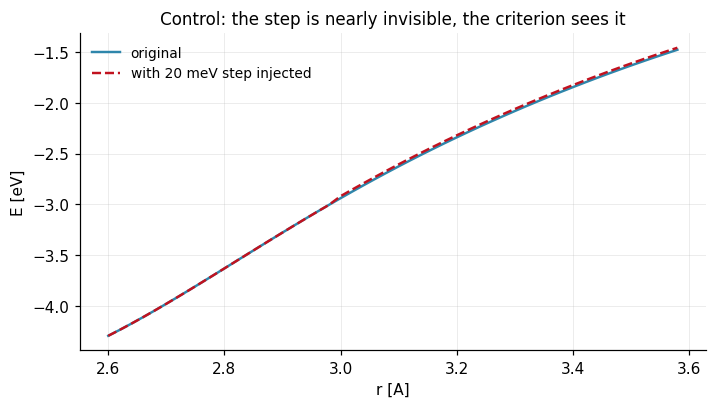

阈值 2.5 干净地分开了两者（3.93 -> 1.21），而所有六条真实曲线的收敛比都在 3.7-3.9 之间。
比值的测量区间为 r = 1.12-7.88 A（两端各裁 3 个粗网格步）。


In [3]:
# The criterion is not re-implemented here: a demo that tests a local copy of
# the logic proves nothing about the framework.  diagnose_pec() is the same
# function run_l1.py uses, and it recomputes every verdict from the curve.
from mlipeval.l1_pes import diagnose_pec

pec = pecs["Ge-Te"]
broken_energy = pec.energy.copy()
broken_energy[pec.r > 3.0] += 0.020          # 20 meV 阶跃
broken = diagnose_pec("Ge-Te", pec.r, broken_energy, pec.force_analytic)

display(pd.DataFrame({
    "内部残差 (h)": [pec.interior_force_mismatch, broken.interior_force_mismatch],
    "收敛比 2h/h": [pec.convergence_ratio, broken.convergence_ratio],
    "判定": ["通过" if pec.convergence_ratio >= THRESHOLDS["pec_convergence_ratio"] else "失败",
             "通过" if broken.convergence_ratio >= THRESHOLDS["pec_convergence_ratio"] else "失败"],
}, index=["原始 Ge-Te", "注入 20 meV 阶跃"]).round(4))

fig, ax = plt.subplots(figsize=(6.4, 3.6))
w = (pec.r > 2.6) & (pec.r < 3.6)
ax.plot(pec.r[w], pec.energy[w], color="#2e86ab", label="original")
ax.plot(pec.r[w], broken_energy[w], color="#c1121f", ls="--", label="with 20 meV step injected")
ax.set_xlabel("r [A]"); ax.set_ylabel("E [eV]"); ax.legend()
ax.set_title("Control: the step is nearly invisible, the criterion sees it")
plt.show()

lo, hi = pec.convergence_window_A
ratios = [q.convergence_ratio for q in pecs.values()]
print(f"阈值 {THRESHOLDS['pec_convergence_ratio']} 干净地分开了两者"
      f"（{pec.convergence_ratio:.2f} -> {broken.convergence_ratio:.2f}），"
      f"而所有六条真实曲线的收敛比都在 {min(ratios):.1f}-{max(ratios):.1f} 之间。\n"
      f"比值的测量区间为 r = {lo:.2f}-{hi:.2f} A（两端各裁 3 个粗网格步）。")


## 2. 不变性、守恒量与解析导数

- **平移不变性**：整体平移不改变能量；
- **旋转不变性**：只对非周期团簇成立（周期性本身破坏旋转对称），所以这一项单独在加真空的团簇上测；
- **净力**：周期体系里所有原子受力之和必须为零；
- **力 vs dE/dx**、**应力 vs dE/dε**：解析导数与数值导数一致。应力的数值侧直接调用
  ASE 自己的 `calculate_numerical_stress`，避免应变约定在两侧漂移。

In [4]:
keys = ["L1.translation_invariance", "L1.rotation_invariance", "L1.net_force",
        "L1.net_torque", "L1.force_vs_dE_dx", "L1.stress_vs_dE_dstrain"]
rows = [{"metric": k, "value": by_id[k]["value"], "unit": by_id[k]["unit"],
         "status": by_id[k]["status"],
         "note": (by_id[k].get("extra") or {}).get("note", "")} for k in keys if k in by_id]
display(pd.DataFrame(rows))

stress = by_id["L1.stress_vs_dE_dstrain"]["extra"]
display(pd.DataFrame({
    "解析 (eV/A^3)": stress["analytic_voigt_eV_per_A3"],
    "数值 (eV/A^3)": stress["numeric_voigt_eV_per_A3"],
}, index=stress["voigt_order"].split()))
print("净力为 0、平移/旋转不变性为 0（float64 精度），说明模型实现本身没有对称性缺陷。")
print("净力矩不为零是周期体系的正常现象，仅作记录，不作判据。")

,metric,value,unit,status,note
0,L1.translation_invariance,9.094947e-13,eV,ok,
1,L1.rotation_invariance,0.000000e+00,eV,ok,evaluated on a non-periodic cluster; PBC breaks rotation...
2,L1.net_force,5.470165e-18,eV/A/atom,ok,
3,L1.net_torque,1.589947e-01,eV/atom,ok,
4,L1.force_vs_dE_dx,2.827453e-06,-,ok,
5,L1.stress_vs_dE_dstrain,4.489803e-09,-,ok,


,解析 (eV/A^3),数值 (eV/A^3)
xx,-0.013696,-0.013696
yy,-0.008853,-0.008853
zz,-0.012086,-0.012086
yz,-0.000312,-0.000312
xz,0.000354,0.000354
xy,-0.000801,-0.000801


净力为 0、平移/旋转不变性为 0（float64 精度），说明模型实现本身没有对称性缺陷。
净力矩不为零是周期体系的正常现象，仅作记录，不作判据。


## 3. 不松弛晶格标度扫描

对 306 原子构型做 0.85–1.15 的各向同性线性缩放，**不松弛**离子。这检查的是 PES 的曲率与光滑性，
不是 EOS（EOS 在 nb03，要求固定体积下松弛离子）。

光滑性判据同样避开绝对阈值：一条光滑曲线在强压缩端本来就曲率大，所以用
"|二阶差分| 的 max/median 离群比"来找**单点**尖峰。

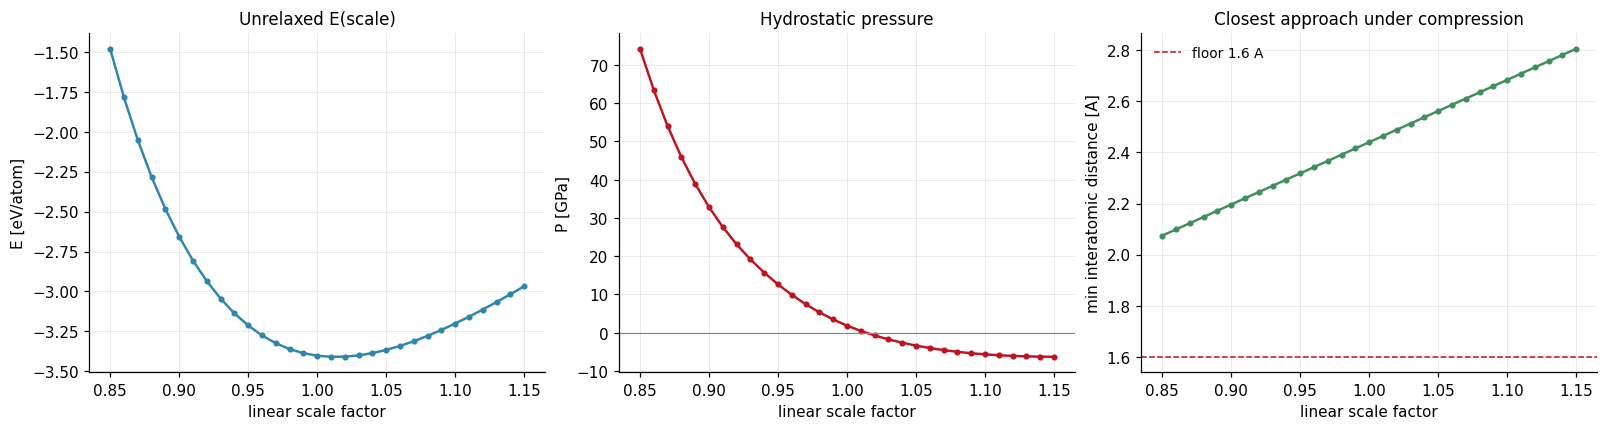

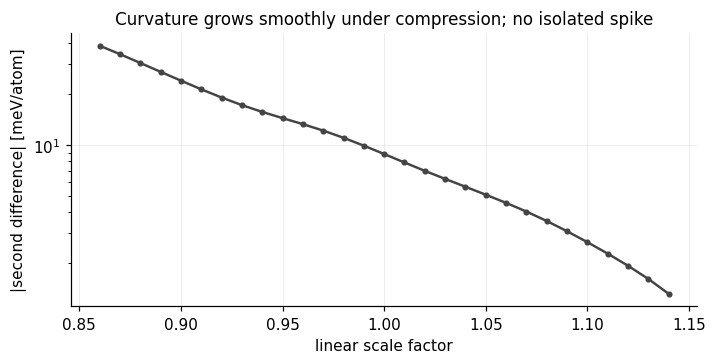

L1.lattice_scan_finite                             31 count              ok
L1.lattice_scan_smoothness                 4.37412288 max/median |d2E|   ok
L1.lattice_scan_compression_monotonic            True -                  ok


In [5]:
scan = np.load(paths.DATA / "l1_lattice_scan.npz")
fig, axes = plt.subplots(1, 3, figsize=(14.5, 3.8))
axes[0].plot(scan["scales"], scan["energy_per_atom"], "o-", ms=3, color="#2e86ab")
axes[0].set_xlabel("linear scale factor"); axes[0].set_ylabel("E [eV/atom]"); axes[0].set_title("Unrelaxed E(scale)")
axes[1].plot(scan["scales"], scan["pressure_gpa"], "o-", ms=3, color="#c1121f")
axes[1].axhline(0, color="#888", lw=0.8)
axes[1].set_xlabel("linear scale factor"); axes[1].set_ylabel("P [GPa]"); axes[1].set_title("Hydrostatic pressure")
axes[2].plot(scan["scales"], scan["min_distance"], "o-", ms=3, color="#3f8f5b")
axes[2].axhline(THRESHOLDS["min_distance_floor"], color="#c1121f", ls="--", lw=1.0,
                label=f"floor {THRESHOLDS['min_distance_floor']} A")
axes[2].set_xlabel("linear scale factor"); axes[2].set_ylabel("min interatomic distance [A]")
axes[2].set_title("Closest approach under compression"); axes[2].legend()
plt.show()

second = np.abs(np.diff(scan["energy_per_atom"], n=2))
fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.semilogy(scan["scales"][1:-1], second * 1000, "o-", ms=3, color="#444")
ax.set_xlabel("linear scale factor"); ax.set_ylabel("|second difference| [meV/atom]")
ax.set_title("Curvature grows smoothly under compression; no isolated spike")
plt.show()

for k in ["L1.lattice_scan_finite", "L1.lattice_scan_smoothness", "L1.lattice_scan_compression_monotonic"]:
    r = by_id[k]
    print(f"{k:42s} {str(r['value'])[:10]:>10s} {r['unit']:18s} {r['status']}")

## 4. 高温稳定性与最小原子间距

2000 K 的 NVT 探针回答两个问题：轨迹会不会崩（NaN / 非物理短键 / 积分发散），
以及**整个过程中原子最近靠到多少**。后者是 L1 里最能预警"短程排斥不够硬"的量——
如果最小间距掉到 1.6 Å 以下，说明模型在高温下允许了非物理的近距接触，
再往下跑 L4/L5 只是在浪费算力。

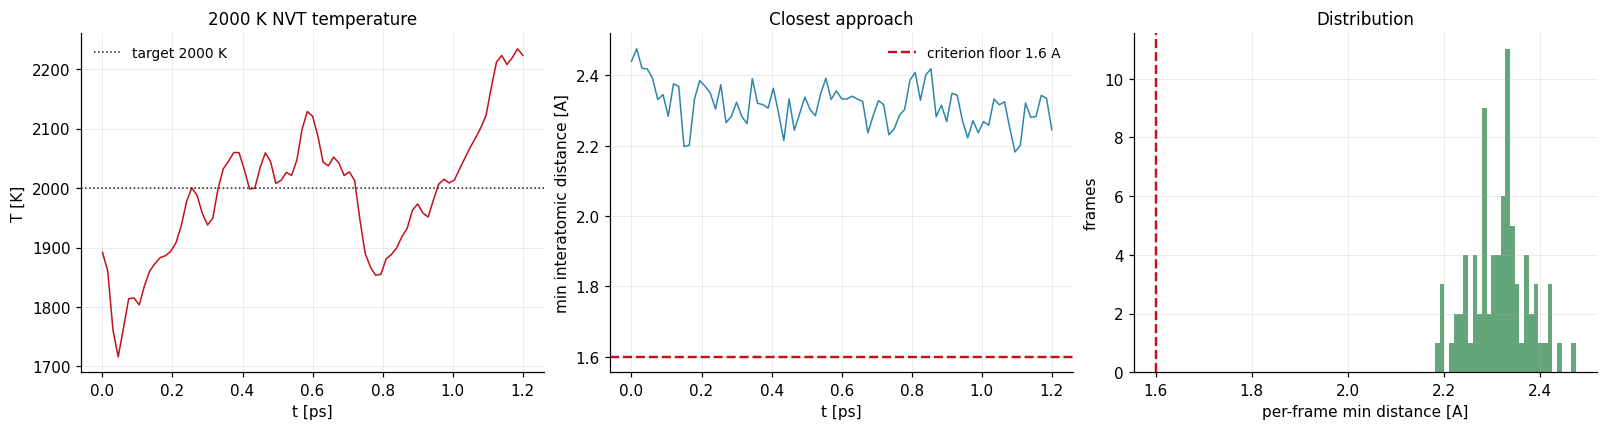

{
  "protocol_id": "mlip_nvt_2000K_hot",
  "ensemble": "nvt",
  "completed": true,
  "crashed_at": null,
  "n_steps": 400,
  "time_ps": 1.2,
  "mean_T_K": 1990.307035239606,
  "min_distance_A": 2.1821665301903503,
  "drift_meV_per_atom_per_ps": 43.18481952849193,
  "max_com_drift_A": 1.3644455783656553e-14,
  "wall_time_s": 10.3
}
L1.stability_2000K.completed                           True ok
L1.stability_2000K.min_distance                2.1821665301 ok
L1.stability_2000K.mean_temperature            1990.3070352 ok


In [6]:
hot = load_md(paths.DATA / "l1_stability_2000K.npz")
t_ps = hot.time_fs / 1000.0

fig, axes = plt.subplots(1, 3, figsize=(14.5, 3.8))
axes[0].plot(t_ps, hot.temperature, lw=1.0, color="#c1121f")
axes[0].axhline(2000, color="#222", ls=":", lw=1.0, label="target 2000 K")
axes[0].set_xlabel("t [ps]"); axes[0].set_ylabel("T [K]"); axes[0].set_title("2000 K NVT temperature")
axes[0].legend()
axes[1].plot(t_ps, hot.min_distance, lw=1.0, color="#2e86ab")
axes[1].axhline(THRESHOLDS["min_distance_floor"], color="#c1121f", ls="--",
                label=f"criterion floor {THRESHOLDS['min_distance_floor']} A")
axes[1].set_xlabel("t [ps]"); axes[1].set_ylabel("min interatomic distance [A]")
axes[1].set_title("Closest approach"); axes[1].legend()
axes[2].hist(hot.min_distance, bins=30, color="#3f8f5b", alpha=0.8)
axes[2].axvline(THRESHOLDS["min_distance_floor"], color="#c1121f", ls="--")
axes[2].set_xlabel("per-frame min distance [A]"); axes[2].set_ylabel("frames")
axes[2].set_title("Distribution")
plt.show()

print(json.dumps(hot.summary(), indent=2))
for k in [k for k in by_id if k.startswith("L1.stability")]:
    print(f"{k:46s} {str(by_id[k]['value'])[:12]:>12s} {by_id[k]['status']}")

## 5. 时间步敏感性与 NVE 漂移

同样的物理时长分别用 3.0 fs 与 1.5 fs 跑，NVE 守恒量的漂移**不应当依赖于时间步**——
如果 3 fs 的漂移显著大于 1.5 fs，说明 3 fs 对这个模型的势能面来说已经太粗。
3.0 fs 是项目 AIMD 的固定选择，1.5 fs 是对照。

NVE 漂移的参考不是一个凭空的阈值，而是 **同协议同体系的 AIMD**：
`H0_preflight_03_nve1200`（306 原子、1200 K、3 fs、333 步）。这让这一项从 S 级升到 **A 级证据**。

AIMD NVE 参考: {
  "drift_meV_per_atom_per_ps": 0.04297748869479389,
  "n_steps": 333,
  "n_atoms": 306,
  "timestep_fs": 3.0,
  "total_time_ps": 0.996,
  "source": "$MLIPEVAL_WORKSPACE/phase1_vasp_inputs_20260828/H0_preflight_03_nve1200/OUTCAR",
  "protocol_id": "gst225_aimd_canonical_v1"
}


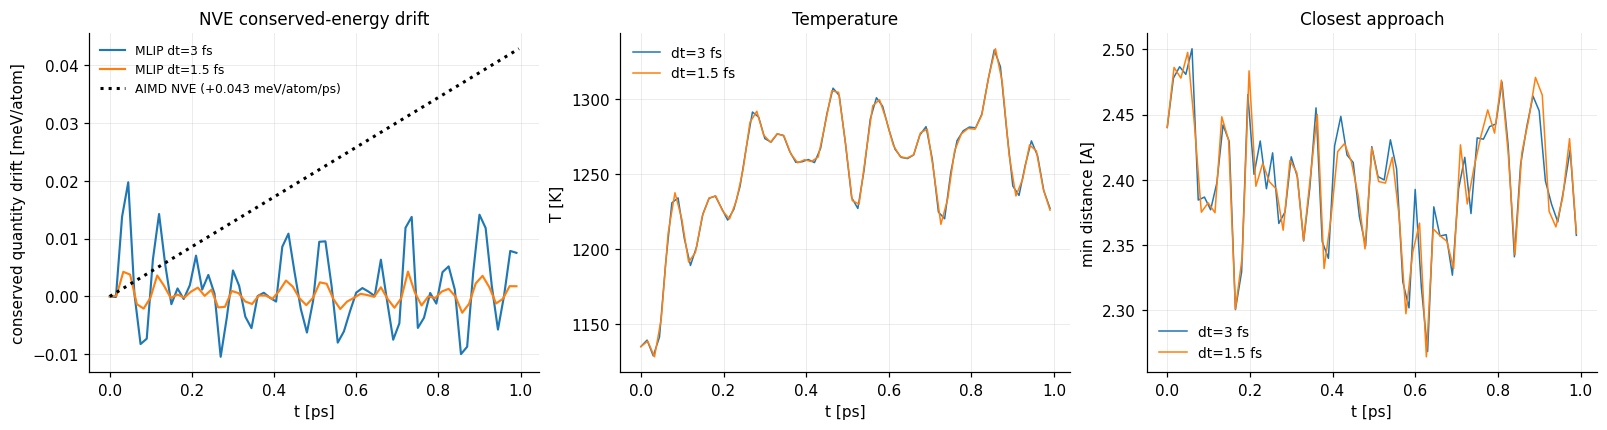

,dt (fs),protocol_id,ensemble,completed,crashed_at,n_steps,time_ps,mean_T_K,min_distance_A,drift_meV_per_atom_per_ps,max_com_drift_A,wall_time_s
0,3.0,mlip_nve_dt3,nvt,True,None,330,0.99,1252.4199,2.2683,-0.0008,0.0,8.5
1,1.5,mlip_nve_dt1.5,nvt,True,None,660,0.99,1252.3420,2.2643,-0.0002,0.0,16.9


In [7]:
aimd = results["context"]["aimd_nve_reference"]
print("AIMD NVE 参考:", json.dumps(aimd, indent=2))

runs = {dt: load_md(paths.DATA / f"l1_nve_dt{dt:g}.npz") for dt in (3.0, 1.5)}
fig, axes = plt.subplots(1, 3, figsize=(14.5, 3.8))
for dt, run in runs.items():
    n = run.trajectory.n_atoms
    e0 = run.total_energy[0]
    axes[0].plot(run.time_fs / 1000.0, (run.total_energy - e0) / n * 1000,
                 label=f"MLIP dt={dt:g} fs", lw=1.4)
    axes[1].plot(run.time_fs / 1000.0, run.temperature, lw=1.0, label=f"dt={dt:g} fs")
    axes[2].plot(run.time_fs / 1000.0, run.min_distance, lw=1.0, label=f"dt={dt:g} fs")

# AIMD 参考斜率画成一条直线，便于直接比较量级
t_ref = np.linspace(0, aimd["total_time_ps"], 20)
axes[0].plot(t_ref, aimd["drift_meV_per_atom_per_ps"] * t_ref, "k:", lw=2.0,
             label=f"AIMD NVE ({aimd['drift_meV_per_atom_per_ps']:+.3f} meV/atom/ps)")
axes[0].set_xlabel("t [ps]"); axes[0].set_ylabel("conserved quantity drift [meV/atom]")
axes[0].set_title("NVE conserved-energy drift"); axes[0].legend(fontsize=8)
axes[1].set_xlabel("t [ps]"); axes[1].set_ylabel("T [K]"); axes[1].set_title("Temperature"); axes[1].legend()
axes[2].set_xlabel("t [ps]"); axes[2].set_ylabel("min distance [A]"); axes[2].set_title("Closest approach"); axes[2].legend()
plt.show()

display(pd.DataFrame([{"dt (fs)": dt, **run.summary()} for dt, run in runs.items()]).round(4))

In [8]:
rows = []
for k in by_id:
    if k.startswith("L1.nve_drift") or k.startswith("L1.com_drift") or k.startswith("L1.timestep"):
        r = by_id[k]
        rows.append({"metric": k, "value": r["value"], "unit": r["unit"], "status": r["status"],
                     "failure_reason": r.get("failure_reason")})
display(pd.DataFrame(rows))

nve = by_id.get("L1.nve_drift.dt=3fs")
if nve:
    e = nve["extra"]
    print(f"\nMLIP 漂移 : {nve['value']:+.4f} meV/atom/ps")
    print(f"AIMD 漂移 : {e['aimd_reference_drift_meV_per_atom_per_ps']:+.4f} meV/atom/ps")
    print(f"比值      : {e['ratio_to_reference']:.2f}x")
    print(f"证据等级  : {nve['evidence_tier']}  （同协议同体系 AIMD 直接对照）")

,metric,value,unit,status,failure_reason
0,L1.timestep_sensitivity.drift_spread,0.000557,meV/atom/ps,ok,None
1,L1.timestep_sensitivity.completed.dt=3fs,True,-,ok,None
2,L1.timestep_sensitivity.completed.dt=1.5fs,True,-,ok,None
3,L1.nve_drift.dt=3fs,-0.000763,meV/atom/ps,ok,None
4,L1.com_drift.dt=3fs,0.0,A,ok,None



MLIP 漂移 : -0.0008 meV/atom/ps
AIMD 漂移 : +0.0430 meV/atom/ps
比值      : 0.02x
证据等级  : A  （同协议同体系 AIMD 直接对照）


## 6. 门控决策

L1 的输出不只是一堆数字，而是一个二值决定：**能不能继续花算力跑 L4/L5**。
任何一条 metric 标 `failed`，门就关上。

In [9]:
gate = results["context"]["gate"]
print(json.dumps(gate, indent=2, ensure_ascii=False))

frame = pd.DataFrame([{
    "metric_id": r["metric_id"], "unit": r["unit"], "status": r["status"],
    "tier": r["evidence_tier"], "failure_reason": r.get("failure_reason"),
} for r in results["results"]])
display(frame)
print("状态分布:", frame.status.value_counts().to_dict())

{
  "pass": true,
  "n_checks": 23,
  "n_failed": 0,
  "failed_metrics": [],
  "decision": "L2-L5 may run"
}


,metric_id,unit,status,tier,failure_reason
0,L1.pec.Ge-Ge,eV,ok,S,None
1,L1.pec.Ge-Sb,eV,ok,S,None
2,L1.pec.Ge-Te,eV,ok,S,None
3,L1.pec.Sb-Sb,eV,ok,S,None
4,L1.pec.Sb-Te,eV,ok,S,None
5,L1.pec.Te-Te,eV,ok,S,None
6,L1.translation_invariance,eV,ok,S,None
7,L1.rotation_invariance,eV,ok,S,None
8,L1.net_force,eV/A/atom,ok,S,None
9,L1.net_torque,eV/atom,ok,S,None


状态分布: {'ok': 23}


## 小结

**通过的项**

- 六条二体 PEC 全部短程单调排斥、无非有限值、能量–力导数残差 2–6×10⁻³，
  且残差随网格加密按 $O(h^2)$ 收敛（内部区间比值 3.7–3.9）→ 势能面连续；
- 平移/旋转不变性与净力在 float64 精度下为 0；力与应力的解析导数同数值导数一致；
- 0.85–1.15 晶格扫描 31 点全部有限、压缩端单调、无曲率尖峰；
- 2000 K NVT 未崩，最小原子间距始终高于判据下限；
- 3.0 fs 与 1.5 fs 的 NVE 漂移差落在容差内 → 项目选定的 3 fs 对该模型可用；
- NVE 漂移与同协议 AIMD 对照（A 级证据）。

**方法上值得留档的一点**

PEC 连续性判据换过三版才站得住。绝对能量跳变阈值和曲率离群比都会被"排斥壁本身很陡"这件事
带偏（六条真实曲线都会被误判）。$O(h^2)$ 收敛比是尺度无关的，但**第一版对全网格取 max 仍然错**：
最内侧那个格点在 $h$ 与 $2h$ 两套网格上不是同一个物理点（见 §2），比值因此不测收敛阶。
现在比值只在内部区间上取（见上面的对照实验，注入 20 meV 阶跃后比值塌到 1.x）。

还有一处与此配套：**缓存原先把判据的结论一并存盘并原样读回**，
于是改判据对任何已缓存的模型静默无效——这个 bug 让上述修正第一次提交时五个模型全部复现了旧比值。
现在 `cache.cached_binary_pecs` 只恢复曲线本身与噪声探针，所有判定由 `l1_pes.diagnose_pec` 重算。

**门控结论**：见上一节。L1 通过即意味着 nb03–nb06 的算力投入是有意义的。